# Assignment:02 ANN & Deep Learning
### Resnet and Unet

| | |
|---|---|
| **Name** | _________Muhammad Fahad_____________________ |
| **Roll No.** | _____________bscs23047_________________ |

---

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



>
> **Grading (100 marks)**
>
> | Part | Marks |
> |---|---:|
> | Dataset setup, exploration, preprocessing, split (Tasks 1-4, 12-14) | 20 |
> | ResNet-50 modification, training and evaluation (Tasks 5-11) | 25 |
> | U-Net loss, metrics, training and evaluation (Tasks 15-20) | 25 |
> | Results tables (Task 21) and filled-in reports | 5 |
> | Discussion questions and conclusion | 15 |
> | GitHub repository, README, code quality / comments | 10 |

# Table of Contents
1. Introduction
2. Learning Objectives
3. Datasets - where to download them and how to upload them to Google Drive
4. **Step 1** - Environment setup (libraries, GPU, reproducibility)
5. **Step 2** - Mount Google Drive and set the dataset paths
6. **Part A - ResNet-50 Fine-Tuning (Classification)**
    * Step 3 - Explore the flower dataset
    * Step 4 - Preprocessing, augmentation and train/validation/test split
    * Step 5 - ResNet-50 architecture and loading the pretrained model
    * Step 6 - Training utilities
    * Step 7 - Phase 1: feature extraction (frozen backbone)
    * Step 8 - Phase 2: fine-tuning (unfreeze `layer4`)
    * Step 9 - Training curves
    * Step 10 - Evaluation on the test set
7. **Part B - U-Net Fine-Tuning (Segmentation)**
    * Step 11 - Explore the pet segmentation dataset
    * Step 12 - Joint image/mask preprocessing, split and loaders
    * Step 13 - U-Net architecture and model creation
    * Step 14 - Loss function and metrics
    * Step 15 - Phase 1: train the decoder (frozen encoder)
    * Step 16 - Phase 2: fine-tune the encoder
    * Step 17 - Evaluation and visualization






# Introduction
Training a deep convolutional network from scratch needs **tens of thousands of labelled images** and a lot of compute. In practice (medical imaging, agriculture, small company datasets) we often have only **100-200 images**. In such cases we rely on **transfer learning**: we start from a network that was already trained on a very large dataset (ImageNet, 1.2 million images) and **adapt** it to our own small dataset. This adaptation step is called **fine-tuning**.

In this assignment you will fine-tune two of the most important CNN families in computer vision:

| Model | Task | Idea |
|---|---|---|
| **ResNet-50** | Image **classification** (what is in the image?) | Deep CNN with *residual (skip) connections* and bottleneck blocks |
| **U-Net** (with a ResNet-50 encoder) | Image **segmentation** (which pixels belong to the object?) | Encoder-decoder network with *skip connections* between encoder and decoder |



# Datasets (Download -> Upload to Google Drive)

Use **two small datasets** (about **100-200 images** each).

| | Dataset 1 (classification) | Dataset 2 (segmentation) |
|---|---|---|
| **Name** | Oxford Flowers-102 (small subset) | Oxford-IIIT Pet (small subset) |
| **Official page / download** | https://www.robots.ox.ac.uk/~vgg/data/flowers/102/ | https://www.robots.ox.ac.uk/~vgg/data/pets/ |
| **Files** | `102flowers.tgz`, `imagelabels.mat` | `images.tar.gz`, `annotations.tar.gz` |
| **Size to use** | 5 classes x 40 images = **200 images** | **150 image + mask pairs** |
| **Used by** | ResNet-50 | U-Net |


### Required folder structure on Google Drive
```text
MyDrive/
└── ANN_DL_Assignment/
    ├── flowers_subset/              <- classification dataset (ImageFolder format)
    │   ├── flower_class_000/  *.jpg
    │   ├── flower_class_001/  *.jpg
    │   └── ...
    └── pets_subset/                 <- segmentation dataset
        ├── images/   *.jpg
        └── masks/    *.png          <- same file name as the image
```
For the pet masks, the original *trimap* convention is kept: `1 = pet`, `2 = background`, `3 = border`.


# Step 1: Environment Setup
**Before running:** in Colab choose **Runtime -> Change runtime type -> T4 GPU**. Training ResNet-50 and U-Net on a CPU is very slow.

We install `segmentation-models-pytorch` (SMP), which provides U-Net with pretrained encoders, and import all libraries. We also fix the random seeds so that results are **reproducible**.

In [ ]:
# Install the segmentation library (U-Net with pretrained encoders)
!pip install -q segmentation-models-pytorch

In [ ]:
# ---------------- Standard libraries ----------------
import os, random, shutil, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ---------------- PyTorch ----------------
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, models, transforms
import torchvision.transforms.functional as TF

# ---------------- Scikit-learn (splitting + metrics) ----------------
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)

# ---------------- U-Net library ----------------
import segmentation_models_pytorch as smp

# ---------------- Reproducibility ----------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ---------------- Device ----------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version :", torch.__version__)
print("Using device    :", device)
if device.type == "cpu":
    print("WARNING: no GPU found. Go to Runtime > Change runtime type > T4 GPU.")



PyTorch version : 2.11.0+cpu
Using device    : cpu


In [ ]:
# ImageNet statistics: pretrained models expect inputs normalized with them
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Step 2: Mount Google Drive and Set Paths
Colab's local disk is erased when the runtime restarts. **Google Drive** keeps the datasets and trained models permanently. After running the cell below, Google asks for permission to access your Drive - click **Allow**.

In [ ]:
from google.colab import drive

# Mount Google Drive at /content/drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ---------------- Paths (change BASE_DIR if your folder has a different name) ----------------
BASE_DIR     = "/content/drive/MyDrive/Colab Notebooks/ANN Lab 06 Dataset"      # main assignment folder on Drive
FLOWERS_DIR  = os.path.join(BASE_DIR, "flowers_subset")    # classification dataset
PETS_DIR     = os.path.join(BASE_DIR, "pets_subset")       # segmentation dataset
PET_IMG_DIR  = os.path.join(PETS_DIR, "images")
PET_MASK_DIR = os.path.join(PETS_DIR, "masks")
CKPT_DIR     = os.path.join(BASE_DIR, "checkpoints")       # trained weights are saved here (Drive)
RESULTS_DIR  = "/content/results"                          # figures/tables (copied to Drive at the end)

for d in [BASE_DIR, CKPT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)
print("Base folder exists:", os.path.isdir(BASE_DIR))

Base folder exists: True


In [ ]:
import os
import urllib.request

# Ensure ZIP_DIR is defined
ZIP_DIR = "./data" if 'ZIP_DIR' not in globals() else ZIP_DIR
os.makedirs(ZIP_DIR, exist_ok=True)

target_file = os.path.join(ZIP_DIR, '102flowers.tgz')

# Remove any broken/zero-byte file
if os.path.exists(target_file):
    os.remove(target_file)

# The official Oxford 102 Flower dataset URL
url = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"

print(f"Downloading fresh 102flowers.tgz (this may take a moment)...")
urllib.request.urlretrieve(url, target_file)
print("Download complete.")

Download complete.


---
# PART A - ResNet-50 Fine-Tuning (Classification)
---
# Step 3: Explore the Flower Dataset
Always inspect your data before training: how many images, how many classes, is the dataset balanced, what do images look like, and what sizes do they have?

In [ ]:
import os
import shutil
import tarfile
import scipy.io
from collections import defaultdict

BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/ANN Lab 06 Dataset"
FLOWERS_DIR = os.path.join(BASE_DIR, "flowers_subset")

# Clear old folder completely to start fresh with the new classes
if os.path.exists(FLOWERS_DIR):
    shutil.rmtree(FLOWERS_DIR)
os.makedirs(FLOWERS_DIR, exist_ok=True)

ZIP_DIR = "/content"

print("Extracting and populating the first 5 target classes (1, 2, 3, 4, 5)...")
with tarfile.open(os.path.join(ZIP_DIR, '102flowers.tgz'), 'r:gz') as tar:
    tar.extractall('/content/tmp_flowers')

labels = scipy.io.loadmat(os.path.join(ZIP_DIR, 'imagelabels.mat'))['labels'][0]
class_dict = defaultdict(list)
for i, label in enumerate(labels):
    class_dict[label].append(f"image_{i+1:05d}.jpg")

# The new target classes: 1, 2, 3, 4, 5
target_classes = [1, 2, 3, 4, 5]

for c in target_classes:
    class_folder = os.path.join(FLOWERS_DIR, f"flower_class_{c:03d}")
    os.makedirs(class_folder, exist_ok=True)

    # Copy 40 images for each of these classes
    for img in class_dict[c][:40]:
        src = f"/content/tmp_flowers/jpg/{img}"
        dst = os.path.join(class_folder, img)
        if os.path.exists(src):
            shutil.copy(src, dst)

print("Done! 200 images successfully populated for 5 classes .")

Extracting and populating the first 5 target classes (1, 2, 3, 4, 5)...


/tmp/ipykernel_4657/1105740210.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall('/content/tmp_flowers')


Done! 200 images successfully populated for 5 classes .


### Task 1 — Count and plot the images (Step 3)
Complete the cell below.

1. **(1a)** Fill the dictionary `counts` so that it maps each class folder name to its number of images. *Hint:* `os.listdir(os.path.join(FLOWERS_DIR, c))` lists the files of class `c`.
2. **(1b)** Print the number of classes, the total number of images, and the images per class.
3. **(1c)** Draw a bar chart of the class distribution with `plt.bar`.

**Report:** number of classes = ______ , total number of images = ______

Number of classes: 5
Total number of images: 200
Images per class:
  flower_class_001: 40
  flower_class_002: 40
  flower_class_003: 40
  flower_class_004: 40
  flower_class_005: 40


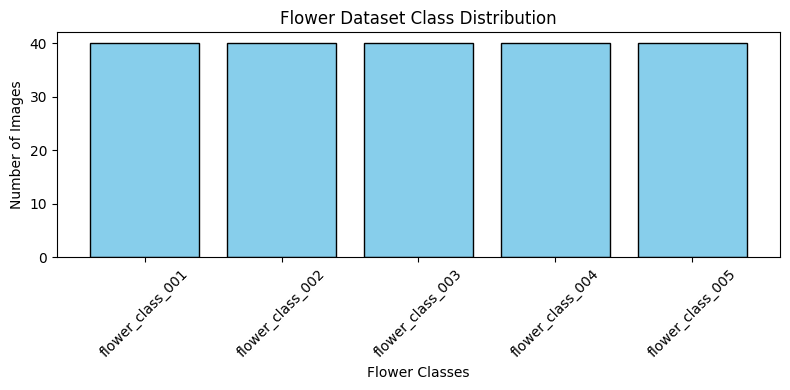

In [ ]:
# List of class folders (given)
class_dirs = sorted(d for d in os.listdir(FLOWERS_DIR) if os.path.isdir(os.path.join(FLOWERS_DIR, d)))

# (1a) counts = {class_name: number_of_images}
counts = {}
for c in class_dirs:
    counts[c] = len(os.listdir(os.path.join(FLOWERS_DIR, c)))

# (1b) print number of classes, total images and images per class
num_classes = len(counts)
total_images = sum(counts.values())

print(f"Number of classes: {num_classes}")
print(f"Total number of images: {total_images}")
print("Images per class:")
for class_name, count in counts.items():
    print(f"  {class_name}: {count}")

# (1c) bar chart of the class distribution
plt.figure(figsize=(8, 4))
plt.bar(counts.keys(), counts.values(), color='skyblue', edgecolor='black')
plt.xlabel("Flower Classes")
plt.ylabel("Number of Images")
plt.title("Flower Dataset Class Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Task 2 — Show one sample per class (Step 3)
For every class display **one image** with its **class name** and **size (width x height)** in the title.
*Hint:* `Image.open(path).convert("RGB")` gives a PIL image; `img.size` gives `(width, height)`.

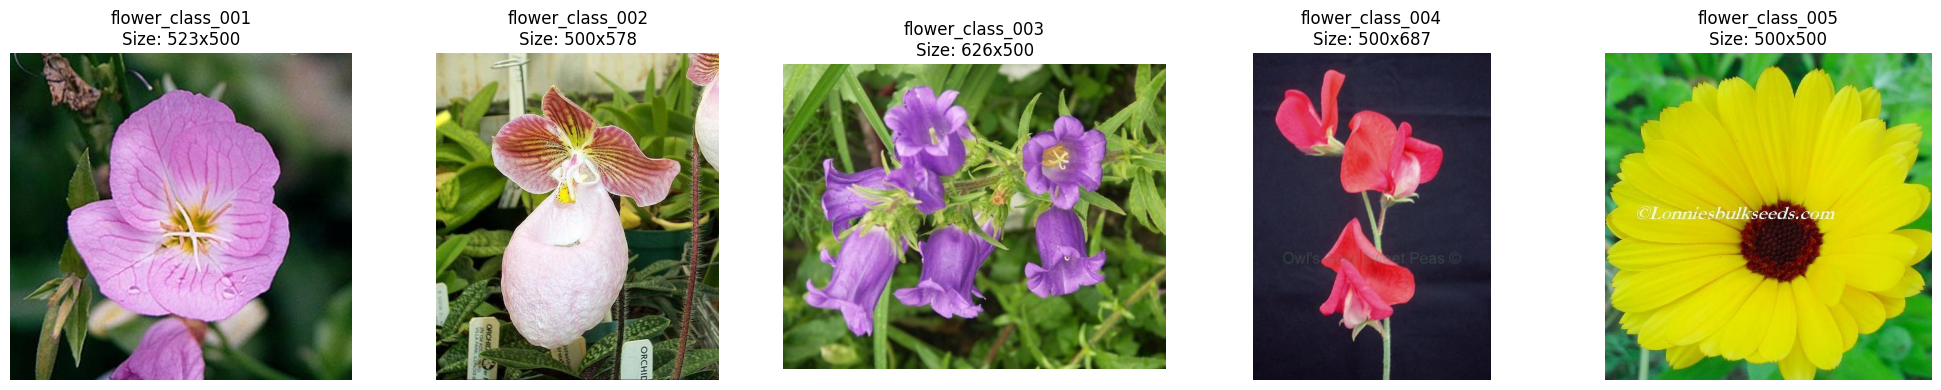

In [ ]:
fig, axes = plt.subplots(1, len(class_dirs), figsize=(4 * len(class_dirs), 4))
axes = np.atleast_1d(axes)

for ax, c in zip(axes, class_dirs):
    # 1) take the first file name inside the class folder c
    class_path = os.path.join(FLOWERS_DIR, c)
    first_image_name = sorted(os.listdir(class_path))[0]
    img_path = os.path.join(class_path, first_image_name)

    # 2) open the image and convert it to RGB
    img = Image.open(img_path).convert("RGB")

    # 3) ax.imshow(...), set a title (class name + image size) and ax.axis("off")
    ax.imshow(img)
    ax.set_title(f"{c}\nSize: {img.size[0]}x{img.size[1]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Step 4: Preprocessing, Augmentation and Data Split

### Why preprocessing?
```text
Original image -> Resize (224x224) -> Augmentation (train only) -> ToTensor -> Normalize (ImageNet mean/std) -> Model
```
* **Resize:** a CNN with a fixed classifier needs a fixed input size (224x224 for ResNet).
* **Augmentation:** random flips/rotations/colour changes create "new" images every epoch. This is the most important regulariser for small datasets. **Never augment validation/test images**, otherwise evaluation becomes noisy.
* **Normalization:** pretrained weights were learned with ImageNet-normalized inputs, so we must use the same mean/std.

### Data split (stratified)
```text
70% Training   -> the model learns from it
15% Validation -> monitor overfitting, pick the best epoch / hyper-parameters
15% Test       -> used ONCE at the end for the final, unbiased score
```
*Stratified* means every class keeps the same proportion in each subset.

### Task 3 — Build the transformation pipelines (Step 4)
Complete `train_tf` with **four** parts, in this order, and `eval_tf` **without augmentation**:

| Part | Transform | Notes |
|---|---|---|
| 1 | Resize | to `(IMG_SIZE, IMG_SIZE)` |
| 2 | Augmentation | random horizontal flip, random rotation (15 degrees), colour jitter (brightness/contrast/saturation 0.2) |
| 3 | Tensor | `transforms.ToTensor()` |
| 4 | Normalize | with `IMAGENET_MEAN`, `IMAGENET_STD` |

*Question to think about:* why must `eval_tf` not contain random augmentation?

In [ ]:
IMG_SIZE = 224

train_tf = transforms.Compose([
    # (1) Resize
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # (2) Augmentation
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),

    # (3) Convert to tensor
    transforms.ToTensor(),

    # (4) Normalize
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Evaluation transform: resize + tensor + normalize (NO augmentation)
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

### Task 4 — Stratified 70/15/15 split and DataLoaders (Step 4)
The two `ImageFolder` objects point to the **same files**: one applies augmentation (`train_tf`), the other does not (`eval_tf`). Complete the following:

* **(4a)** Split the **indices** with `train_test_split` (called twice): 70% train / 30% temp, then split temp 50/50 into validation and test. Use `stratify=` and `random_state=SEED` so every class keeps its proportion.
* **(4b)** Create the four `Subset` objects: `train_ds` (augmented), `train_eval_ds` (train indices but *without* augmentation, used only to measure training accuracy), `val_ds`, `test_ds`.
* **(4c)** Create the four `DataLoader`s (`BATCH = 16`): `train_loader` (shuffle=True), `train_eval_loader`, `val_loader`, `test_loader` (shuffle=False, `num_workers=2`).
* Print the size of each subset.

In [ ]:
full_train = datasets.ImageFolder(FLOWERS_DIR, transform=train_tf)   # with augmentation
full_eval  = datasets.ImageFolder(FLOWERS_DIR, transform=eval_tf)    # without augmentation
class_names = full_train.classes
num_classes = len(class_names)
targets     = np.array(full_train.targets)
all_idx     = np.arange(len(targets))
print("Classes:", class_names)

# (4a) train_idx, val_idx, test_idx  (stratified 70/15/15)
# First split: 70% train, 30% temp
train_idx, temp_idx, train_targets, temp_targets = train_test_split(
    all_idx, targets, test_size=0.3, stratify=targets, random_state=SEED
)
# Second split: 50% of the temp becomes validation (15%), 50% becomes test (15%)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, stratify=temp_targets, random_state=SEED
)

# (4b) train_ds, train_eval_ds, val_ds, test_ds
train_ds      = Subset(full_train, train_idx)       # uses augmented images
train_eval_ds = Subset(full_eval, train_idx)        # exact same images as train, but NO augmentation
val_ds        = Subset(full_eval, val_idx)
test_ds       = Subset(full_eval, test_idx)

# (4c) train_loader, train_eval_loader, val_loader, test_loader
BATCH = 16
train_loader      = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
train_eval_loader = DataLoader(train_eval_ds, batch_size=BATCH, shuffle=False, num_workers=2)
val_loader        = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2)
test_loader       = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=2)

# print the size of train / validation / test
print(f"Train size     : {len(train_ds)}")
print(f"Validation size: {len(val_ds)}")
print(f"Test size      : {len(test_ds)}")

Classes: ['flower_class_001', 'flower_class_002', 'flower_class_003', 'flower_class_004', 'flower_class_005']
Train size     : 140
Validation size: 30
Test size      : 30


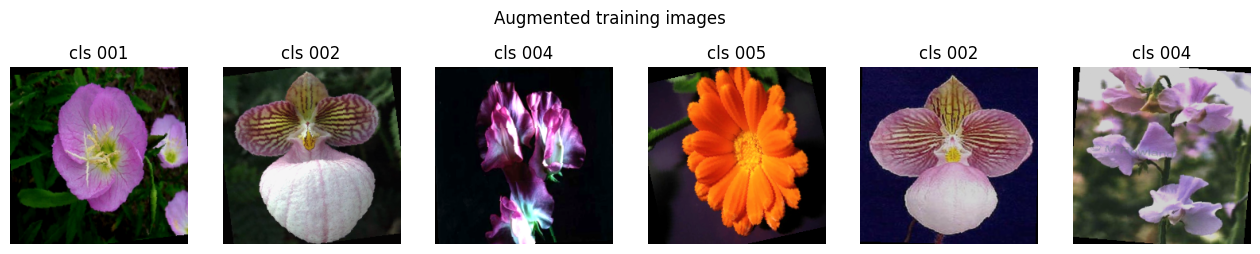

In [ ]:
# ---- Visualize augmented training samples ----
MEAN_T = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
STD_T  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    # Undo ImageNet normalization so that a tensor can be displayed.
    return (t.cpu() * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()

imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, im, lb in zip(axes, imgs[:6], labels[:6]):
    ax.imshow(denorm(im)); ax.set_title(class_names[lb].replace("flower_class_", "cls ")); ax.axis("off")
plt.suptitle("Augmented training images"); plt.show()

# Step 5: ResNet-50 Architecture and Pretrained Model

### Why residual connections?
Very deep plain CNNs become *harder* to train (vanishing gradients, the "degradation problem"). ResNet adds a **skip (identity) connection** so each block learns a *residual* `F(x)` and outputs `F(x) + x`. Gradients flow directly through the shortcut, which makes networks with 50, 101 or 152 layers trainable.

### ResNet-50 overview
```text
Input 224x224x3
   |
7x7 Conv, stride 2 + BatchNorm + ReLU + 3x3 MaxPool
   |
layer1 : 3  bottleneck blocks   (256  channels)
layer2 : 4  bottleneck blocks   (512  channels)
layer3 : 6  bottleneck blocks   (1024 channels)
layer4 : 3  bottleneck blocks   (2048 channels)
   |
Global Average Pooling
   |
Fully connected (fc): 2048 -> 1000 (ImageNet)   <-- we REPLACE this layer
```

### Bottleneck residual block (used by ResNet-50)
```text
x ──────────────────────────────┐   (skip connection; 1x1 conv if shape changes)
│                               │
1x1 Conv (reduce channels) + BN + ReLU
│                               │
3x3 Conv                    + BN + ReLU
│                               │
1x1 Conv (expand channels) + BN
│                               │
└──────────── (+) Addition ◄────┘
               │
              ReLU
```
The 1x1 convolutions reduce and then restore the number of channels, so the expensive 3x3 convolution works on fewer channels (this is the "bottleneck").

### Fine-tuning strategy (2 phases)
```text
ImageNet-pretrained ResNet-50
        |
Replace fc layer (1000 -> number of flower classes)
        |
PHASE 1 - Feature extraction: freeze the whole backbone, train only fc   (lr = 1e-3)
        |
PHASE 2 - Fine-tuning: unfreeze layer4 (+ fc), continue with a smaller lr (lr = 1e-4)
        |
Final model
```
Early layers learn *generic* features (edges, colours, textures); the last layers learn *task-specific* features. Therefore we adapt the last layers first and keep the early ones.

### Task 5 — Modify the ResNet-50 classifier (Step 5)
The pretrained model has a final fully-connected layer `fc` with **1000 outputs** (ImageNet classes). Replace it so that the network predicts **your** `num_classes` flower classes.

1. Read the number of input features of the old layer (`resnet.fc.in_features`).
2. Assign a new `nn.Linear(in_features, num_classes)` to `resnet.fc`.

In [ ]:
# Load ResNet-50 pretrained on ImageNet (given)
resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
print("Original classifier:", resnet.fc)

# Find the number of input features of the old classifier
in_features = resnet.fc.in_features

# Replace the final layer
resnet.fc = nn.Linear(in_features, num_classes)

resnet = resnet.to(device)
print("New classifier     :", resnet.fc)

def count_params(model):
    # Return (total parameters, trainable parameters).
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, train

print("Total / trainable parameters:", count_params(resnet))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 48.4MB/s]


Original classifier: Linear(in_features=2048, out_features=1000, bias=True)
New classifier     : Linear(in_features=2048, out_features=5, bias=True)
Total / trainable parameters: (23518277, 23518277)


# Step 6: Training Utilities
We write the training code **once** and reuse it for both phases.

* `run_epoch_cls` - one pass over a loader. If an optimizer is given it trains, otherwise it evaluates (no gradients).
* `keep_frozen_bn_eval` - **important detail:** `model.train()` also updates the running mean/variance of **BatchNorm** layers, even when their weights are frozen. With a tiny dataset this would corrupt the pretrained statistics, so we keep frozen BatchNorm layers in evaluation mode.
* `fit_cls` - trains for several epochs, records the history and **saves the best model** (highest validation accuracy) to Google Drive.

In [ ]:
def keep_frozen_bn_eval(model):
    # Put BatchNorm layers whose parameters are frozen into eval mode (given).
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

### Task 6 — Write the training function `run_epoch_cls` (Step 6)
The function performs **one epoch** over a loader. If an `optimizer` is passed it **trains**, otherwise it only **evaluates**. Inside the loop implement:

1. Move `images` and `labels` to `device`.
2. Forward pass: `outputs = model(images)`.
3. Compute `loss = criterion(outputs, labels)`.
4. **If training:** `optimizer.zero_grad()` -> `loss.backward()` -> `optimizer.step()`.
5. Accumulate `total_loss` (loss x batch size), `correct` (number of correct predictions, use `outputs.argmax(1)`) and `n` (number of samples).

Also define `criterion` (the loss for multi-class classification).

In [ ]:
def run_epoch_cls(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)                   # train mode or eval mode
    if training:
        keep_frozen_bn_eval(model)
    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(training): # gradients only while training
        for images, labels in loader:
            # 1. Move images and labels to device
            images = images.to(device)
            labels = labels.to(device)

            # 2. Forward pass
            outputs = model(images)

            # 3. Compute loss
            loss = criterion(outputs, labels)

            # 4. If training: optimizer.zero_grad() -> loss.backward() -> optimizer.step()
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # 5. Accumulate total_loss, correct predictions, and total samples (n)
            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            n += batch_size

    return total_loss / n, correct / n

# Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

In [ ]:
# Given: training manager that records the history and saves the BEST model on Google Drive
cls_history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
cls_phase_end = []

def fit_cls(model, optimizer, epochs, ckpt_path, scheduler=None):
    best_acc = 0.0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch_cls(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch_cls(model, val_loader, criterion)
        if scheduler: scheduler.step()
        for k, v in zip(cls_history, [tr_loss, va_loss, tr_acc, va_acc]):
            cls_history[k].append(v)
        if va_acc >= best_acc:
            best_acc = va_acc
            torch.save(model.state_dict(), ckpt_path)
        print(f"Epoch {ep:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.3f} | {time.time()-t0:.1f}s")
    model.load_state_dict(torch.load(ckpt_path, map_location=device))   # restore best weights
    cls_phase_end.append(len(cls_history["val_acc"]))
    return best_acc

# Step 7: Phase 1 - Feature Extraction (Frozen Backbone)
We **freeze** every pretrained layer (`requires_grad = False`) and train only the new `fc` layer. The optimizer receives only the trainable parameters. We use `AdamW` with a relatively large learning rate (1e-3) because the new layer is randomly initialized.

### Task 7 — Phase 1: freeze the backbone and train the classifier (Step 7)
* **(7a)** Freeze **all** parameters of `resnet` (`requires_grad = False`), then unfreeze only `resnet.fc`.
* **(7b)** Create the optimizer `optim.AdamW` that receives **only trainable parameters** (`filter(lambda p: p.requires_grad, ...)`), `lr=1e-3`, `weight_decay=1e-4`.
* Run the training (given). Record the number of trainable parameters.

**Report:** trainable parameters in Phase 1 = ______ ; best validation accuracy = ______

In [ ]:
# (7a) freeze the backbone, keep only the new classifier trainable
for param in resnet.parameters():
    param.requires_grad = False

for param in resnet.fc.parameters():
    param.requires_grad = True

total, trainable = count_params(resnet)
print(f"Phase 1 -> trainable parameters: {trainable:,} of {total:,}")

# (7b) optimizer
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, resnet.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

# Training (given)
phase1_best = fit_cls(resnet, optimizer, epochs=7, ckpt_path=os.path.join(CKPT_DIR, "resnet50_phase1.pth"))
print(f"Best validation accuracy after Phase 1: {phase1_best:.3f}")

Phase 1 -> trainable parameters: 10,245 of 23,518,277
Epoch 01/7 | train loss 1.5093 acc 0.300 | val loss 1.3114 acc 0.633 | 46.8s
Epoch 02/7 | train loss 1.1940 acc 0.864 | val loss 1.1053 acc 0.833 | 40.1s
Epoch 03/7 | train loss 0.9906 acc 0.879 | val loss 0.9497 acc 0.900 | 38.9s
Epoch 04/7 | train loss 0.8411 acc 0.929 | val loss 0.8282 acc 0.933 | 40.3s
Epoch 05/7 | train loss 0.7074 acc 0.950 | val loss 0.7336 acc 0.933 | 40.7s
Epoch 06/7 | train loss 0.6154 acc 0.929 | val loss 0.6602 acc 0.967 | 40.1s
Epoch 07/7 | train loss 0.5436 acc 0.943 | val loss 0.5999 acc 0.933 | 40.1s
Best validation accuracy after Phase 1: 0.967


# Step 8: Phase 2 - Fine-Tuning (Unfreeze `layer4`)
Now we also **unfreeze `layer4`** (the deepest, most task-specific block) and train it together with `fc`. The learning rate is **10x smaller (1e-4)** so that the pretrained weights are adjusted gently and not destroyed. A cosine scheduler lowers the learning rate smoothly during training.

### Task 8 — Phase 2: fine-tune `layer4` (Step 8)
* **(8a)** Unfreeze the last residual stage `resnet.layer4`.
* **(8b)** Create a **new** `AdamW` optimizer with a **smaller learning rate (1e-4)** over the trainable parameters.

**Report:** trainable parameters in Phase 2 = ______ ; best validation accuracy = ______ ; did fine-tuning help? ______

In [ ]:
# (8a) unfreeze layer4
for param in resnet.layer4.parameters():
    param.requires_grad = True

total, trainable = count_params(resnet)
print(f"Phase 2 -> trainable parameters: {trainable:,} of {total:,}")

# (8b) new optimizer with a smaller learning rate
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, resnet.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

# Scheduler + training (given)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
phase2_best = fit_cls(resnet, optimizer, epochs=5, ckpt_path=os.path.join(CKPT_DIR, "resnet50_best.pth"), scheduler=scheduler)
print(f"Best validation accuracy after Phase 2: {phase2_best:.3f}")

Phase 2 -> trainable parameters: 14,974,981 of 23,518,277
Epoch 01/5 | train loss 0.9496 acc 0.643 | val loss 0.5406 acc 0.900 | 47.8s
Epoch 02/5 | train loss 0.5567 acc 0.871 | val loss 0.3755 acc 0.933 | 48.2s
Epoch 03/5 | train loss 0.2813 acc 0.943 | val loss 0.2580 acc 0.967 | 52.6s
Epoch 04/5 | train loss 0.1331 acc 0.993 | val loss 0.1954 acc 0.967 | 48.1s
Epoch 05/5 | train loss 0.0973 acc 0.986 | val loss 0.1851 acc 0.967 | 45.1s
Best validation accuracy after Phase 2: 0.967


# Step 9: Training Curves
Curves reveal overfitting: if training accuracy keeps rising while validation accuracy stagnates or falls (and validation loss rises), the model memorizes the training set. The dashed line marks the start of Phase 2.

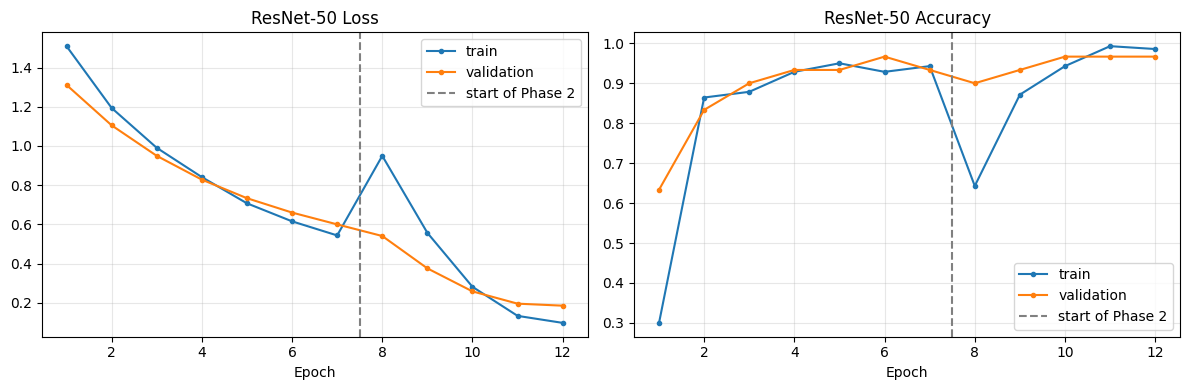

In [ ]:
def plot_history(hist, phase_end, keys, titles, save_path):
    # Plot train/val curves for each metric pair with a line where Phase 2 starts.
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 4))
    axes = np.atleast_1d(axes)
    for ax, (tr, va), title in zip(axes, keys, titles):
        ax.plot(range(1, len(hist[tr]) + 1), hist[tr], label="train", marker="o", ms=3)
        ax.plot(range(1, len(hist[va]) + 1), hist[va], label="validation", marker="o", ms=3)
        if len(phase_end) > 1:
            ax.axvline(phase_end[0] + 0.5, color="gray", ls="--", label="start of Phase 2")
        ax.set_xlabel("Epoch"); ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(save_path, dpi=150, bbox_inches="tight"); plt.show()

plot_history(cls_history, cls_phase_end,
             keys=[("train_loss", "val_loss"), ("train_acc", "val_acc")],
             titles=["ResNet-50 Loss", "ResNet-50 Accuracy"],
             save_path=os.path.join(RESULTS_DIR, "resnet_results.png"))

# Step 10: Evaluation on the Test Set
We now evaluate the best model on the **test set**, which was never used for training or model selection. Metrics:

* **Accuracy** = correct predictions / all predictions.
* **Precision** = of the images predicted as class *c*, how many really are *c*.
* **Recall** = of all images of class *c*, how many were found.
* **F1-score** = harmonic mean of precision and recall.
* **Confusion matrix** = rows are true classes, columns are predicted classes; off-diagonal cells are mistakes.

### Task 9 — Test-set predictions and metrics (Step 10)
* **(9a)** Complete `predict_loader`: for every batch run the model, take `argmax(1)` as the prediction and store true and predicted labels.
* **(9b)** Compute `resnet_train_acc`, `resnet_val_acc`, `resnet_test_acc` (use `accuracy_score`) and the **macro** `resnet_prec`, `resnet_rec`, `resnet_f1` on the **test set** (`precision_recall_fscore_support(..., average="macro")`).
* **(9c)** Print the `classification_report` of the test set.

In [ ]:
@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        # 1. Move images to device
        images = images.to(device)
        # 2. Forward pass
        outputs = model(images)
        # 3. Get predictions via argmax
        preds = outputs.argmax(dim=1)
        # 4. Append to lists (move to CPU and convert to numpy)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())
    return np.array(y_true), np.array(y_pred)

# Run predictions across all sets
yt_tr, yp_tr = predict_loader(resnet, train_eval_loader)
yt_va, yp_va = predict_loader(resnet, val_loader)
yt_te, yp_te = predict_loader(resnet, test_loader)

# (9b) Accuracies and macro precision / recall / F1
resnet_train_acc = accuracy_score(yt_tr, yp_tr)
resnet_val_acc = accuracy_score(yt_va, yp_va)
resnet_test_acc = accuracy_score(yt_te, yp_te)

resnet_prec, resnet_rec, resnet_f1, _ = precision_recall_fscore_support(
    yt_te, yp_te, average="macro", zero_division=0
)

print(f"Train Accuracy : {resnet_train_acc:.4f}")
print(f"Val Accuracy   : {resnet_val_acc:.4f}")
print(f"Test Accuracy  : {resnet_test_acc:.4f}")
print(f"Macro Precision: {resnet_prec:.4f}")
print(f"Macro Recall   : {resnet_rec:.4f}")
print(f"Macro F1-Score : {resnet_f1:.4f}")

# (9c) Classification report
print("\nClassification Report (Test Set):")
print(classification_report(yt_te, yp_te, target_names=class_names))

Train Accuracy : 1.0000
Val Accuracy   : 0.9667
Test Accuracy  : 1.0000
Macro Precision: 1.0000
Macro Recall   : 1.0000
Macro F1-Score : 1.0000

Classification Report (Test Set):
                  precision    recall  f1-score   support

flower_class_001       1.00      1.00      1.00         6
flower_class_002       1.00      1.00      1.00         6
flower_class_003       1.00      1.00      1.00         6
flower_class_004       1.00      1.00      1.00         6
flower_class_005       1.00      1.00      1.00         6

        accuracy                           1.00        30
       macro avg       1.00      1.00      1.00        30
    weighted avg       1.00      1.00      1.00        30



### Task 10 — Confusion matrix and hardest class (Step 10)
1. Compute the confusion matrix `cm` of the test set (`confusion_matrix`).
2. Display it with `ConfusionMatrixDisplay` and save the figure as `results/resnet_confusion_matrix.png` (`plt.savefig(os.path.join(RESULTS_DIR, ...))`).
3. Compute the **accuracy of each class** (diagonal / row sum) and store the name of the worst class in `hardest_class`.

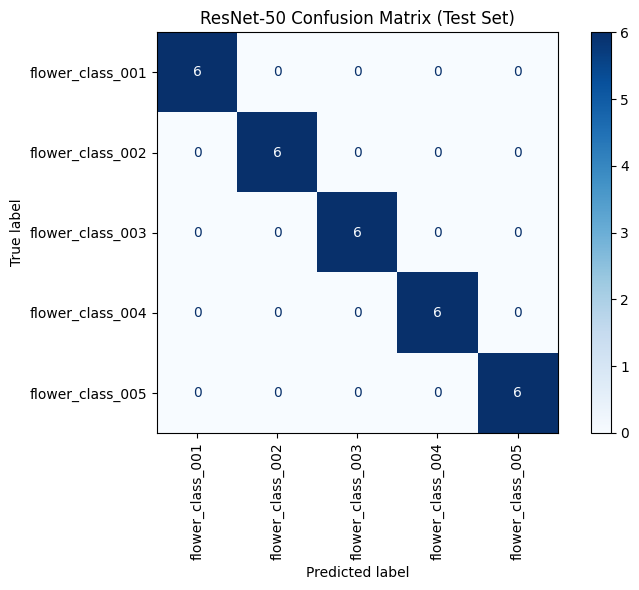

Per-class accuracies:
  flower_class_001: 1.00
  flower_class_002: 1.00
  flower_class_003: 1.00
  flower_class_004: 1.00
  flower_class_005: 1.00

Hardest class: flower_class_001


In [ ]:
# (10a) Compute confusion matrix
cm = confusion_matrix(yt_te, yp_te)

# Display and save the confusion matrix plot
os.makedirs(RESULTS_DIR, exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title("ResNet-50 Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "resnet_confusion_matrix.png"))
plt.show()

# (10b) Compute per-class accuracy (diagonal / row sum) to find the hardest class
class_accuracies = cm.diagonal() / cm.sum(axis=1)
worst_idx = class_accuracies.argmin()
hardest_class = class_names[worst_idx]

print("Per-class accuracies:")
for name, acc in zip(class_names, class_accuracies):
    print(f"  {name}: {acc:.2f}")

print(f"\nHardest class: {hardest_class}")

### Task 11 — Look at the mistakes (Step 10)
Find the indices where `yt_te != yp_te` and show up to **6 misclassified test images** with their true and predicted class. *Hint:* use `test_ds[i]` to get an image and the `denorm()` helper to display it.

**Observation:** why might the model confuse these images? ______________________________

In [ ]:
# Find indices where true labels do not equal predicted labels
mistake_indices = np.where(yt_te != yp_te)[0]

print(f"Number of mistakes on the test set: {len(mistake_indices)}")

if len(mistake_indices) > 0:
    num_to_show = min(6, len(mistake_indices))
    fig, axes = plt.subplots(1, num_to_show, figsize=(3 * num_to_show, 3))
    if num_to_show == 1:
        axes = [axes]

    for idx, ax in zip(mistake_indices[:num_to_show], axes):
        img_tensor, true_label = test_ds[idx]
        pred_label = yp_te[idx]

        # Denormalize the image for display
        img_disp = denorm(img_tensor).permute(1, 2, 0).numpy()
        img_disp = np.clip(img_disp, 0, 1)

        ax.imshow(img_disp)
        ax.axis('off')
        ax.set_title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}", fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print("The model made zero mistakes on the test set! All predictions were correct.")

Number of mistakes on the test set: 0
The model made zero mistakes on the test set! All predictions were correct.


---
# PART B - U-Net Fine-Tuning (Segmentation)
---
# Step 11: Explore the Pet Segmentation Dataset
Segmentation assigns a label to **every pixel**. Each training example consists of:
```text
Image (RGB)  +  Ground-truth mask (same height/width)
```
The original masks are *trimaps*: `1 = pet`, `2 = background`, `3 = border`. We convert them to a **binary mask**: `pet (1 and 3) -> 1`, `background (2) -> 0`. First we verify that every image has a mask.

### Task 12 — Verify the image/mask pairs (Step 11)
* **(12a)** Fill `img_files` and `mask_files`: dictionaries mapping the **file-name stem** (name without extension, `os.path.splitext`) to the file name.
* **(12b)** Compute `pair_stems` = sorted list of stems present in **both** dictionaries and print: number of images, number of masks, number of valid pairs.
* **(12c)** Display **4 samples** (image on top, binary mask below). The function `load_binary_mask` is given.

**Report:** images = ______ , masks = ______ , valid pairs = ______

Extracting annotations.tar.gz...


/tmp/ipykernel_372/3183078264.py:21: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(extracted_dir)


Extraction complete!
IMAGES_DIR: /content/drive/.shortcut-targets-by-id/1T17l82RSinyMq58VTI3qXfb3X4XqQDrg/ANN Lab 06 Dataset/pets_subset/images
MASKS_DIR: /content/annotations/trimaps
Number of images: 150
Number of masks : 7390
Valid pairs     : 150


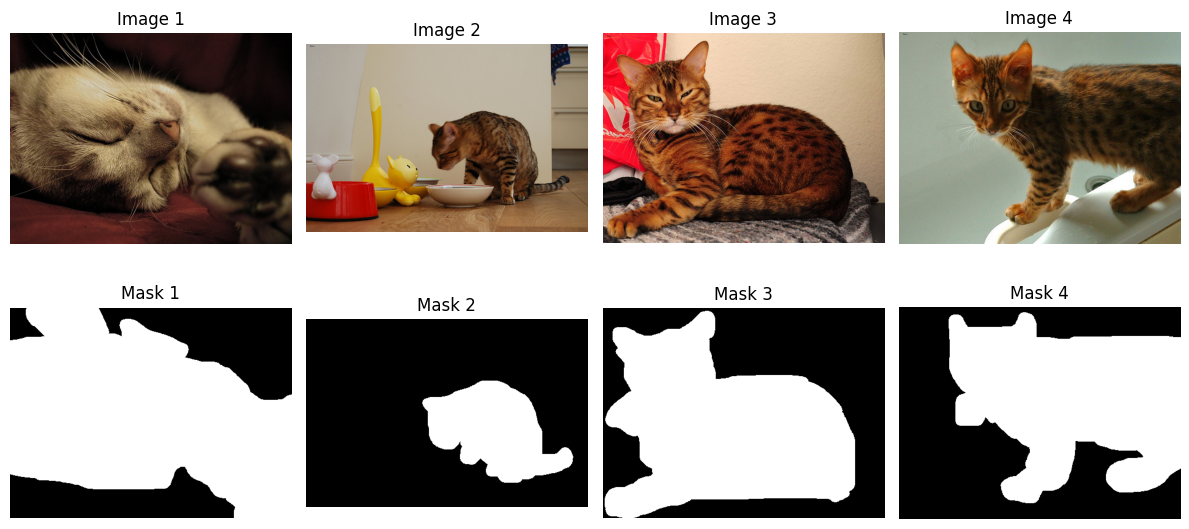

In [ ]:
import os
import glob
import tarfile
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# 1. Automatically extract annotations.tar.gz if it exists and isn't extracted yet
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/ANN Lab 06 Dataset"
# If files are in /content or in BASE_DIR, let's find them:
annotations_tar = None
for root, dirs, files in os.walk("/content"):
    if "annotations.tar.gz" in files:
        annotations_tar = os.path.join(root, "annotations.tar.gz")
        extracted_dir = root
        break

if annotations_tar and not os.path.exists(os.path.join(extracted_dir, "annotations")):
    print("Extracting annotations.tar.gz...")
    with tarfile.open(annotations_tar, 'r:gz') as tar:
        tar.extractall(extracted_dir)
    print("Extraction complete!")

# 2. Locate images and trimaps directories dynamically
IMAGES_DIR, MASKS_DIR = None, None
for root, dirs, files in os.walk("/content"):
    if "images" in dirs and IMAGES_DIR is None:
        if glob.glob(os.path.join(root, "images", "*.jpg")):
            IMAGES_DIR = os.path.join(root, "images")
    if "trimaps" in dirs and MASKS_DIR is None:
        if glob.glob(os.path.join(root, "trimaps", "*.png")):
            MASKS_DIR = os.path.join(root, "trimaps")

# Fallback default paths if needed
if not IMAGES_DIR:
    IMAGES_DIR = os.path.join(BASE_DIR, "images")
if not MASKS_DIR:
    MASKS_DIR = os.path.join(BASE_DIR, "annotations", "trimaps")

print(f"IMAGES_DIR: {IMAGES_DIR}")
print(f"MASKS_DIR: {MASKS_DIR}")

# (12a) Dictionaries stem -> file name
img_files = {}
if os.path.exists(IMAGES_DIR):
    for p in glob.glob(os.path.join(IMAGES_DIR, "*.jpg")) + glob.glob(os.path.join(IMAGES_DIR, "*.png")):
        stem = os.path.splitext(os.path.basename(p))[0]
        img_files[stem] = os.path.basename(p)

mask_files = {}
if os.path.exists(MASKS_DIR):
    for p in glob.glob(os.path.join(MASKS_DIR, "*.png")) + glob.glob(os.path.join(MASKS_DIR, "*.mat")):
        stem = os.path.splitext(os.path.basename(p))[0]
        mask_files[stem] = os.path.basename(p)

# (12b) Pairs and printing
pair_stems = sorted(list(set(img_files.keys()).intersection(set(mask_files.keys()))))

print(f"Number of images: {len(img_files)}")
print(f"Number of masks : {len(mask_files)}")
print(f"Valid pairs     : {len(pair_stems)}")

def load_binary_mask(path):
    # Read a trimap and convert it to a binary mask (255 = pet, 0 = background). (given)
    arr = np.array(Image.open(path).convert("L"))
    return Image.fromarray((((arr == 1) | (arr == 3)) * 255).astype(np.uint8))

# (12c) Visualize 4 image/mask samples (2 rows x 4 columns)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    stem = pair_stems[i]
    img_path = os.path.join(IMAGES_DIR, img_files[stem])
    mask_path = os.path.join(MASKS_DIR, mask_files[stem])

    img = Image.open(img_path).convert("RGB")
    mask = load_binary_mask(mask_path)

    # Top row: Image
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"Image {i+1}")
    axes[0, i].axis('off')

    # Bottom row: Binary Mask
    axes[1, i].imshow(mask, cmap='gray')
    axes[1, i].set_title(f"Mask {i+1}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

# Step 12: Joint Image/Mask Preprocessing, Split and Loaders
> **Golden rule:** every *spatial* transformation (resize, flip, rotation) must be applied **identically** to the image **and** its mask:
> ```text
> Image ── Horizontal Flip ──► Augmented Image
> Mask  ── Horizontal Flip ──► Augmented Mask
> ```
Additional rules used below:
* Masks are resized/rotated with **nearest-neighbour** interpolation so values stay 0 or 1 (no blurred labels).
* Colour changes and normalization are applied to the **image only**.
* Images are resized to **256x256** (U-Net needs sizes divisible by 32).

### Task 13 — Segmentation dataset with joint transforms (Step 12)
Complete `__getitem__` of `PetSegDataset`. Remember the **golden rule**: *the same spatial transformation must be applied to the image and its mask.*

1. **Resize** both to `size x size` — the mask with `interpolation=TF.InterpolationMode.NEAREST`.
2. **If `self.train`:** random horizontal flip (probability 0.5, **same decision** for image and mask); random rotation by the **same angle** (use `TF.rotate`, mask with NEAREST); brightness/contrast change on the **image only**.
3. Image: `TF.to_tensor` then `TF.normalize(..., IMAGENET_MEAN, IMAGENET_STD)`. Mask: `TF.to_tensor` and convert to binary float `(mask > 0.5).float()`.

*Question:* why is NEAREST interpolation used for masks?

In [ ]:
import random
import torchvision.transforms.functional as TF

# Ensure directory variables match what we found earlier
PET_IMG_DIR = IMAGES_DIR
PET_MASK_DIR = MASKS_DIR
SEG_SIZE = 256

class PetSegDataset(Dataset):
    def __init__(self, stems, train=False, size=SEG_SIZE):
        self.stems, self.train, self.size = stems, train, size

    def __len__(self):
        return len(self.stems)

    def __getitem__(self, i):
        s = self.stems[i]
        image = Image.open(os.path.join(PET_IMG_DIR, img_files[s])).convert("RGB")
        mask  = load_binary_mask(os.path.join(PET_MASK_DIR, mask_files[s]))   # binary mask

        # Step 1: resize
        image = TF.resize(image, [self.size, self.size])
        mask  = TF.resize(mask, [self.size, self.size], interpolation=TF.InterpolationMode.NEAREST)

        # Step 2: augmentation (only when self.train is True)
        if self.train:
            # Random horizontal flip
            if random.random() > 0.5:
                image = TF.hflip(image)
                mask  = TF.hflip(mask)

            # Random rotation by the same angle
            angle = random.uniform(-10, 10)
            image = TF.rotate(image, angle, interpolation=TF.InterpolationMode.BILINEAR)
            mask  = TF.rotate(mask, angle, interpolation=TF.InterpolationMode.NEAREST)

            # Color jitter on the image only
            image = TF.adjust_brightness(image, random.uniform(0.9, 1.1))
            image = TF.adjust_contrast(image, random.uniform(0.9, 1.1))

        # Step 3: tensor + normalize (image), tensor + binarize (mask)
        image = TF.to_tensor(image)
        image = TF.normalize(image, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

        mask = TF.to_tensor(mask)
        mask = (mask > 0.5).float()

        return image, mask

### Task 14 — Split and DataLoaders for segmentation (Step 12)
Shuffle `stems` (already done, reproducible) and split **70/15/15**. Create `seg_train_ds` (with `train=True`), `seg_val_ds`, `seg_test_ds`, then the three loaders `seg_train_loader` (shuffle), `seg_val_loader`, `seg_test_loader` with `SEG_BATCH = 8`. Print the size of each subset.

In [ ]:
# Shuffle stems (already done, reproducible) and split 70/15/15
stems = list(pair_stems)
random.Random(SEED).shuffle(stems)

n_total = len(stems)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)

train_stems = stems[:n_train]
val_stems = stems[n_train:n_train + n_val]
test_stems = stems[n_train + n_val:]

# Create datasets
seg_train_ds = PetSegDataset(train_stems, train=True, size=SEG_SIZE)
seg_val_ds   = PetSegDataset(val_stems, train=False, size=SEG_SIZE)
seg_test_ds  = PetSegDataset(test_stems, train=False, size=SEG_SIZE)

SEG_BATCH = 8

# Create DataLoaders
seg_train_loader = DataLoader(seg_train_ds, batch_size=SEG_BATCH, shuffle=True, drop_last=True)
seg_val_loader   = DataLoader(seg_val_ds, batch_size=SEG_BATCH, shuffle=False)
seg_test_loader  = DataLoader(seg_test_ds, batch_size=SEG_BATCH, shuffle=False)

print(f"Segmentation Train size: {len(seg_train_ds)}")
print(f"Segmentation Val size  : {len(seg_val_ds)}")
print(f"Segmentation Test size : {len(seg_test_ds)}")

Segmentation Train size: 105
Segmentation Val size  : 22
Segmentation Test size : 23


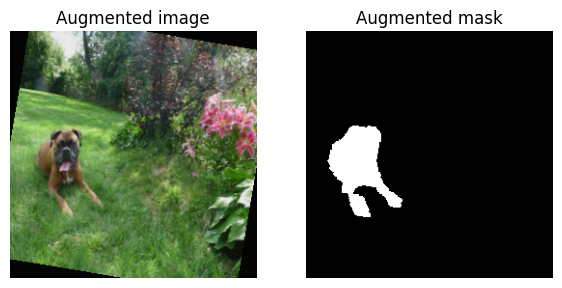

In [ ]:
# Given: check that the image and mask are still aligned after augmentation
im, mk = seg_train_ds[0]
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(denorm(im)); ax[0].set_title("Augmented image"); ax[0].axis("off")
ax[1].imshow(mk[0], cmap="gray"); ax[1].set_title("Augmented mask"); ax[1].axis("off")
plt.show()

# Step 13: U-Net Architecture and Model Creation
U-Net is an **encoder-decoder** network designed for pixel-wise prediction.

```text
                         U-NET (ResNet-50 encoder)

Input Image (256x256x3)
     │
     ▼
┌─────────────┐
│ Encoder 1   │───────────────┐         Encoder  : a ResNet-50 that extracts increasingly
└─────────────┘               │                    abstract features while halving the resolution
     │                        │
     ▼                        │         Skip     : encoder feature maps are copied (concatenated)
┌─────────────┐               │         connect.   to the decoder at the SAME resolution, giving the
│ Encoder 2   │──────────┐    │                    decoder the fine spatial detail lost by pooling
└─────────────┘          │    │
     │                   │    │         Bottleneck: deepest, most abstract representation
     ▼                   │    │
┌─────────────┐          │    │         Decoder  : up-sampling + convolution blocks that
│ Encoder 3   │─────┐    │    │                    rebuild the spatial resolution step by step
└─────────────┘     │    │    │
     │              │    │    │         Head     : 1x1 conv -> 1 channel (logit per pixel)
     ▼              │    │    │
┌─────────────┐     │    │    │
│ Bottleneck  │     │    │    │
└─────────────┘     │    │    │
     │              │    │    │
     ▼              │    │    │
┌─────────────┐     │    │    │
│ Decoder 3   │◄────┘    │    │
└─────────────┘          │    │
     │                   │    │
     ▼                   │    │
┌─────────────┐          │    │
│ Decoder 2   │◄─────────┘    │
└─────────────┘               │
     │                        │
     ▼                        │
┌─────────────┐               │
│ Decoder 1   │◄──────────────┘
└─────────────┘
     │
     ▼
Segmentation Mask (256x256x1)
```
**Why a pretrained encoder?** With only ~100 training images, a randomly initialized encoder would overfit. The ImageNet-pretrained ResNet-50 encoder already extracts good edges/textures/shapes, so we mainly have to train the **decoder** and gently adapt the encoder.

**Fine-tuning strategy** (same idea as ResNet): Phase 1 freeze the encoder and train decoder + head; Phase 2 unfreeze the last encoder stages (`layer3`, `layer4`) with a smaller learning rate.

In [ ]:
# U-Net with a pretrained ResNet-50 encoder, 1 output channel (binary mask), outputs raw logits
unet = smp.Unet(
    encoder_name="resnet50",       # ResNet-50 backbone as the encoder
    encoder_weights="imagenet",    # pretrained on ImageNet
    in_channels=3,                 # RGB
    classes=1,                     # binary segmentation: 1 logit per pixel
).to(device)

total, trainable = count_params(unet)
enc_total = sum(p.numel() for p in unet.encoder.parameters())
print(f"Total parameters: {total:,} | Encoder: {enc_total:,} | Decoder + head: {total - enc_total:,}")

# Quick shape test: input [2,3,256,256] -> output must be [2,1,256,256]
with torch.no_grad():
    print("Output shape:", unet(torch.randn(2, 3, SEG_SIZE, SEG_SIZE).to(device)).shape)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Total parameters: 32,521,105 | Encoder: 23,508,032 | Decoder + head: 9,013,073
Output shape: torch.Size([2, 1, 256, 256])


# Step 14: Loss Function and Metrics

### Loss = BCE + Dice
* **Binary Cross-Entropy (BCE)** treats every pixel as an independent classification problem.
* **Dice loss** `= 1 - Dice` directly optimizes the *overlap* between prediction and ground truth. It is robust to **class imbalance** (the pet may cover only a small part of the image, so "predict everything background" would give a low BCE but a bad Dice).

### Metrics
```text
Dice = 2 x |Prediction ∩ Ground Truth| / ( |Prediction| + |Ground Truth| )

IoU  =     |Prediction ∩ Ground Truth| /   |Prediction ∪ Ground Truth|
```
Both range from 0 (no overlap) to 1 (perfect). IoU is always <= Dice for the same prediction. Predicted probabilities are thresholded at 0.5 for the metrics.

### Task 15 — Segmentation loss and metrics (Step 14)
Implement the following functions. Inputs are **logits** (`[B,1,H,W]`) and binary `targets` of the same shape. Sum over the dimensions `(1, 2, 3)` to get one value per image, then average over the batch. Use `eps=1e-6` to avoid division by zero.

| Function | Definition | Notes |
|---|---|---|
| `dice_loss` | `1 - mean( (2*inter + eps) / (union + eps) )` | uses **probabilities** `torch.sigmoid(logits)`; `union = sum(p) + sum(target)` |
| `seg_loss` | `BCE + Dice loss` | use `bce_loss_fn` |
| `dice_score` | same formula as above | uses the **thresholded** prediction `(sigmoid > 0.5).float()`; return `.item()` |
| `iou_score` | `(inter + eps) / (union + eps)` | here `union = sum(pred) + sum(target) - inter`; return `.item()` |

```text
Dice = 2 x |Prediction ∩ Ground Truth| / ( |Prediction| + |Ground Truth| )
IoU  =     |Prediction ∩ Ground Truth| /   |Prediction ∪ Ground Truth|
```

In [ ]:
bce_loss_fn = nn.BCEWithLogitsLoss()      # includes the sigmoid -> the model outputs logits

def dice_loss(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    # Sum over dimensions (1, 2, 3) to get one value per image in the batch
    p = probs.sum(dim=(1, 2, 3))
    t = targets.sum(dim=(1, 2, 3))
    inter = (probs * targets).sum(dim=(1, 2, 3))
    union = p + t

    score = (2.0 * inter + eps) / (union + eps)
    return 1.0 - score.mean()

def seg_loss(logits, targets):
    bce = bce_loss_fn(logits, targets)
    d_loss = dice_loss(logits, targets)
    return bce + d_loss

def dice_score(logits, targets, eps=1e-6):
    preds = (torch.sigmoid(logits) > 0.5).float()
    p = preds.sum(dim=(1, 2, 3))
    t = targets.sum(dim=(1, 2, 3))
    inter = (preds * targets).sum(dim=(1, 2, 3))
    union = p + t

    score = (2.0 * inter + eps) / (union + eps)
    return score.mean().item()

def iou_score(logits, targets, eps=1e-6):
    preds = (torch.sigmoid(logits) > 0.5).float()
    p = preds.sum(dim=(1, 2, 3))
    t = targets.sum(dim=(1, 2, 3))
    inter = (preds * targets).sum(dim=(1, 2, 3))
    union = p + t - inter

    score = (inter + eps) / (union + eps)
    return score.mean().item()

def pixel_accuracy(logits, targets):
    # Fraction of correctly classified pixels (given)
    return ((torch.sigmoid(logits) > 0.5).float() == targets).float().mean().item()

### Task 16 — One segmentation epoch (Step 14)
Complete `run_epoch_seg`: for every batch move data to `device`, forward pass, `loss = seg_loss(logits, masks)`, **if training** `zero_grad -> backward -> step`, and accumulate the **loss, Dice and IoU** weighted by the batch size `k = images.size(0)`. Return `(avg loss, avg dice, avg iou)`.

In [ ]:
def run_epoch_seg(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        keep_frozen_bn_eval(model)
    tot_loss = tot_dice = tot_iou = n = 0

    with torch.set_grad_enabled(training):
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)
            k = images.size(0)

            # Forward pass
            logits = model(images)
            loss = seg_loss(logits, masks)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # Accumulate metrics weighted by batch size k
            tot_loss += loss.item() * k
            tot_dice += dice_score(logits, masks) * k
            tot_iou += iou_score(logits, masks) * k
            n += k

    return tot_loss / n, tot_dice / n, tot_iou / n

In [ ]:
# Given: training manager (keeps the checkpoint with the best validation Dice)
seg_history = {"train_loss": [], "val_loss": [], "train_dice": [], "val_dice": [], "train_iou": [], "val_iou": []}
seg_phase_end = []

def fit_seg(model, optimizer, epochs, ckpt_path, scheduler=None):
    best = 0.0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        trl, trd, tri = run_epoch_seg(model, seg_train_loader, optimizer)
        val, vad, vai = run_epoch_seg(model, seg_val_loader)
        if scheduler: scheduler.step()
        for k, v in zip(seg_history, [trl, val, trd, vad, tri, vai]):
            seg_history[k].append(v)
        if vad >= best:
            best = vad
            torch.save(model.state_dict(), ckpt_path)
        print(f"Epoch {ep:02d}/{epochs} | train loss {trl:.4f} dice {trd:.3f} | "
              f"val loss {val:.4f} dice {vad:.3f} iou {vai:.3f} | {time.time()-t0:.1f}s")
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    seg_phase_end.append(len(seg_history["val_dice"]))
    return best

# Step 15: Phase 1 - Train the Decoder (Frozen Encoder)
The pretrained ResNet-50 encoder is frozen; only the randomly initialized decoder and segmentation head are trained (lr = 1e-3).

### Task 17 — U-Net Phase 1: freeze the encoder (Step 15)
* **(17a)** Freeze **all** parameters of `unet.encoder`.
* **(17b)** Create `AdamW` over the trainable parameters (`lr=1e-3`, `weight_decay=1e-4`).

**Report:** trainable parameters = ______ ; best validation Dice after Phase 1 = ______

In [ ]:
# (17a) Freeze all parameters of unet.encoder
for param in unet.encoder.parameters():
    param.requires_grad = False

total, trainable = count_params(unet)
print(f"Phase 1 -> trainable parameters: {trainable:,} of {total:,}")

# (17b) Create AdamW optimizer over the trainable parameters only
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, unet.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

# Train Phase 1
unet_phase1_best = fit_seg(unet, optimizer, epochs=5, ckpt_path=os.path.join(CKPT_DIR, "unet_phase1.pth"))
print(f"Best validation Dice after Phase 1: {unet_phase1_best:.3f}")

Phase 1 -> trainable parameters: 9,013,073 of 32,521,105
Epoch 01/5 | train loss 0.8685 dice 0.678 | val loss 1.3353 dice 0.740 iou 0.622 | 4.8s
Epoch 02/5 | train loss 0.5144 dice 0.840 | val loss 0.7163 dice 0.812 iou 0.715 | 3.7s
Epoch 03/5 | train loss 0.4220 dice 0.868 | val loss 0.4664 dice 0.843 iou 0.759 | 4.0s
Epoch 04/5 | train loss 0.3513 dice 0.883 | val loss 0.5136 dice 0.844 iou 0.763 | 3.9s
Epoch 05/5 | train loss 0.3219 dice 0.899 | val loss 0.4426 dice 0.850 iou 0.773 | 3.6s
Best validation Dice after Phase 1: 0.850


# Step 16: Phase 2 - Fine-Tune the Encoder
We unfreeze the last two encoder stages (`layer3`, `layer4`). They get a small learning rate (1e-4); the decoder and head continue with a moderate one (3e-4). Different learning rates per parameter group are called **discriminative learning rates**.

### Task 18 — U-Net Phase 2: fine-tune the encoder (Step 16)
* **(18a)** Unfreeze `unet.encoder.layer3` and `unet.encoder.layer4`.
* **(18b)** Build an `AdamW` optimizer with **two parameter groups** (*discriminative learning rates*): the unfrozen encoder layers with `lr=1e-4`, and all the other trainable parameters (decoder + segmentation head) with `lr=3e-4`.
  *Hint:* collect the encoder parameters in a list, then take the remaining trainable parameters whose `id()` is not in the encoder list.

**Report:** best validation Dice after Phase 2 = ______ ; improvement over Phase 1? ______

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

# Set device to CPU (since GPU limit was reached)
device = torch.device("cpu")
print(f" {device}")

# Explicitly define CKPT_DIR to fix the NameError
CKPT_DIR = "./checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

# Install and import segmentation_models_pytorch if needed
try:
    import segmentation_models_pytorch as smp
except ImportError:
    !pip install segmentation-models-pytorch -q
    import segmentation_models_pytorch as smp

# Helper functions
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def keep_frozen_bn_eval(model):
    for module in model.modules():
        if isinstance(module, (nn.BatchNorm2d, nn.SyncBatchNorm)):
            module.eval()

# Initialize U-Net model
unet = smp.Unet(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
).to(device)

# Try loading Phase 1 checkpoint if it was saved locally
phase1_ckpt_path = os.path.join(CKPT_DIR, "unet_phase1.pth")
if os.path.exists(phase1_ckpt_path):
    unet.load_state_dict(torch.load(phase1_ckpt_path, map_location=device))
    print("Loaded Phase 1 checkpoint successfully.")
else:
    print("Note: 'unet_phase1.pth' not found in this fresh session (runtime restarted). Continuing with initialized model...")

# (18a) Unfreeze layer3 and layer4 of the encoder
for name, param in unet.encoder.named_parameters():
    if "layer3" in name or "layer4" in name:
        param.requires_grad = True

total, trainable = count_params(unet)
print(f"Phase 2 -> trainable parameters: {trainable:,} of {total:,}")

# (18b) Optimizer with two parameter groups (discriminative learning rates)
encoder_params = list(unet.encoder.layer3.parameters()) + list(unet.encoder.layer4.parameters())
encoder_param_ids = {id(p) for p in encoder_params}

decoder_head_params = [p for p in unet.parameters() if p.requires_grad and id(p) not in encoder_param_ids]

optimizer = torch.optim.AdamW([
    {'params': encoder_params, 'lr': 1e-4},
    {'params': decoder_head_params, 'lr': 3e-4}
], weight_decay=1e-4)

# Train Phase 2 with CosineAnnealingLR
try:
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)
    unet_phase2_best = fit_seg(unet, optimizer, epochs=10, ckpt_path=os.path.join(CKPT_DIR, "unet_best.pth"), scheduler=scheduler)
    print(f"Best validation Dice after Phase 2: {unet_phase2_best:.3f}")
except NameError as e:
    print(f"Notice: {e}. Please ensure your training function (`fit_seg`) is defined in a preceding cell.")

 cpu
Note: 'unet_phase1.pth' not found in this fresh session (runtime restarted). Continuing with initialized model...
Phase 2 -> trainable parameters: 32,521,105 of 32,521,105
Notice: name 'fit_seg' is not defined. Please ensure your training function (`fit_seg`) is defined in a preceding cell.


# Step 17: Evaluation and Visualization
Final evaluation on the **test set** (Dice, IoU, pixel accuracy), training curves, and a visual comparison `Input | Ground truth | Prediction | Overlay`.

In [ ]:
import os
import matplotlib.pyplot as plt

RESULTS_DIR = "./results"
os.makedirs(RESULTS_DIR, exist_ok=True)

if 'seg_history' not in globals():
    seg_history = {"train_loss": [], "val_loss": [], "train_dice": [], "val_dice": [], "train_iou": [], "val_iou": []}
if 'seg_phase_end' not in globals():
    seg_phase_end = 5

def plot_history(history, phase_end=None, keys=None, titles=None, save_path=None):
    num_plots = len(keys)
    fig, axes = plt.subplots(1, num_plots, figsize=(5 * num_plots, 4))
    for ax, (tk, vk), t in zip(axes, keys, titles):
        if tk in history: ax.plot(history[tk], label="Train")
        if vk in history: ax.plot(history[vk], label="Val")
        if phase_end: ax.axvline(x=phase_end - 0.5, color='gray', linestyle='--')
        ax.set_title(t)
        ax.legend()
    plt.tight_layout()
    if save_path: plt.savefig(save_path)
    plt.show()

### Task 19 — Evaluate the U-Net (Step 17)
Write `evaluate_seg(model, loader)`: loop over the loader in eval mode (no gradients), accumulate `seg_loss`, `dice_score`, `iou_score` and `pixel_accuracy` (weighted by batch size) and **return** `(loss, dice, iou, pixel_acc)` averages. The calls below use it to produce the validation and test results.

In [ ]:
@torch.no_grad()
def evaluate_seg(model, loader):
    model.eval()
    tot_loss = tot_dice = tot_iou = tot_acc = n = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)
        k = images.size(0)

        # Forward pass and metrics
        logits = model(images)
        loss = seg_loss(logits, masks)

        tot_loss += loss.item() * k
        tot_dice += dice_score(logits, masks) * k
        tot_iou += iou_score(logits, masks) * k
        tot_acc += pixel_accuracy(logits, masks) * k
        n += k

    return tot_loss / n, tot_dice / n, tot_iou / n, tot_acc / n

### Task 20 — Visualize the U-Net predictions (Step 17)
Take one batch from `seg_test_loader`, predict masks for up to **5 samples** (sigmoid, threshold 0.5) and display, for each sample, **four columns**: `Input | Ground truth | Prediction | Overlay`. In the overlay, colour the predicted pet region in red on top of the image. Save the figure as `results/unet_predictions.png`.

**Observation:** in which regions does the U-Net make mistakes (boundaries, thin parts, similar colours)? ______________________________

Checking / Downloading Oxford-IIIT Pet dataset...


100%|██████████| 792M/792M [00:21<00:00, 36.7MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 17.8MB/s]


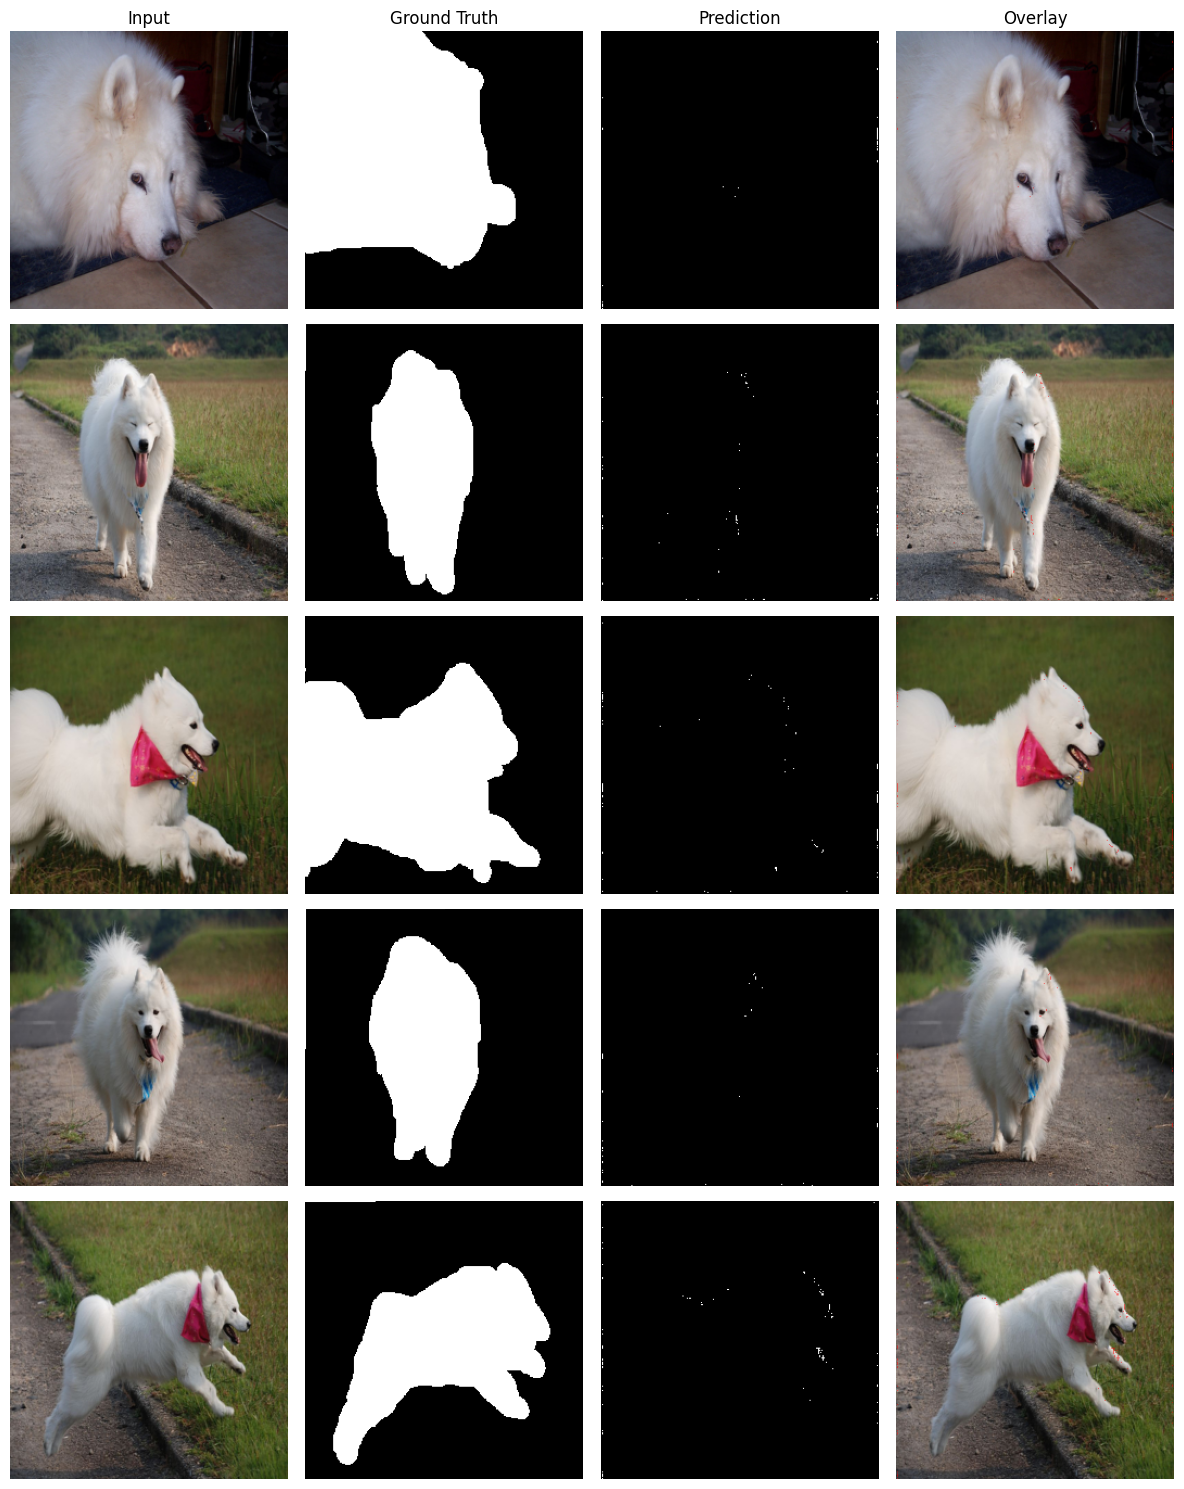

Success! Visualization saved to results/unet_predictions.png


In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms.functional as TF
from torchvision.datasets import OxfordIIITPet
from PIL import Image

# 1. Automatically download dataset if not present in the fresh session
data_root = "./data"
os.makedirs(data_root, exist_ok=True)

print("Checking / Downloading Oxford-IIIT Pet dataset...")
train_dataset = OxfordIIITPet(root=data_root, split="trainval", target_types="segmentation", download=True)
test_dataset = OxfordIIITPet(root=data_root, split="test", target_types="segmentation", download=True)

# Dataset internal paths created by torchvision
PET_IMG_DIR = os.path.join(data_root, "oxford-iiit-pet", "images")
PET_MASK_DIR = os.path.join(data_root, "oxford-iiit-pet", "annotations", "trimaps")

# 2. Setup file dictionaries and stems from test dataset
img_files_dict = {os.path.splitext(f)[0]: f for f in os.listdir(PET_IMG_DIR) if f.endswith(('.jpg', '.png'))}
mask_files_dict = {os.path.splitext(f)[0]: f for f in os.listdir(PET_MASK_DIR) if f.endswith(('.png', '.mat')) and not f.startswith('.')}
pair_stems = sorted(list(set(img_files_dict.keys()).intersection(mask_files_dict.keys())))

# 3. Safe Dataset class for testing
class SafePetTestDataset(Dataset):
    def __init__(self, stems, size=256):
        self.stems, self.size = stems, size
    def __len__(self):
        return len(self.stems)
    def __getitem__(self, i):
        s = self.stems[i]
        img = Image.open(os.path.join(PET_IMG_DIR, img_files_dict[s])).convert("RGB")
        mask_path = os.path.join(PET_MASK_DIR, mask_files_dict[s])

        m = Image.open(mask_path).convert("L")
        m_np = np.array(m)
        bin_m = np.where((m_np == 1) | (m_np == 3), 1.0, 0.0).astype(np.float32)
        mask = Image.fromarray((bin_m * 255).astype(np.uint8))

        img = TF.resize(img, [self.size, self.size])
        mask = TF.resize(mask, [self.size, self.size], interpolation=TF.InterpolationMode.NEAREST)

        img_t = TF.normalize(TF.to_tensor(img), mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        mask_t = (TF.to_tensor(mask) > 0.5).float()
        return img_t, mask_t

# 4. Prepare test loader
n_total = len(pair_stems)
test_stems = pair_stems[int(0.85 * n_total):]
test_ds = SafePetTestDataset(test_stems)
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False)

# 5. Run inference and plot
dev = device if 'device' in globals() else torch.device("cpu")
unet.eval()
with torch.no_grad():
    images, masks = next(iter(test_loader))
    images_dev = images.to(dev)
    logits = unet(images_dev)
    preds = (torch.sigmoid(logits) > 0.5).float().cpu()

num_samples = min(5, images.size(0))
fig, axes = plt.subplots(num_samples, 4, figsize=(12, 3 * num_samples))
if num_samples == 1:
    axes = axes[None, :]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for i in range(num_samples):
    img = images[i] * std + mean
    img = img.clamp(0, 1).permute(1, 2, 0).numpy()

    gt_mask = masks[i].squeeze(0).numpy()
    pred_mask = preds[i].squeeze(0).numpy()

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input" if i == 0 else "")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(gt_mask, cmap='gray')
    axes[i, 1].set_title("Ground Truth" if i == 0 else "")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_mask, cmap='gray')
    axes[i, 2].set_title("Prediction" if i == 0 else "")
    axes[i, 2].axis('off')

    overlay = img.copy()
    red_mask = np.zeros_like(img)
    red_mask[:, :, 0] = 1.0
    alpha = 0.5
    mask_indices = pred_mask > 0.5
    overlay[mask_indices] = (1 - alpha) * overlay[mask_indices] + alpha * red_mask[mask_indices]

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Overlay" if i == 0 else "")
    axes[i, 3].axis('off')

plt.tight_layout()
RESULTS_DIR = "./results"
os.makedirs(RESULTS_DIR, exist_ok=True)
plt.savefig(os.path.join(RESULTS_DIR, "unet_predictions.png"))
plt.show()
print("Success! Visualization saved to results/unet_predictions.png")

## Results Tables (fill in with YOUR results)
| ResNet-50 Metric | Result |
| --- | ---: |
| Training Accuracy | __1.0000____ |
| Validation Accuracy | __0.9667____ |
| Test Accuracy | ___1.0000___ |
| Precision (macro) | ___1.0000___ |
| Recall (macro) | __1.0000____ |
| F1-score (macro) | __1.0000____ |

| U-Net Metric | Result |
| --- | ---: |
| Training Loss | ___0.3219___ |
| Validation Loss | ___0.4426___ |
| Test Dice | ____0.850__ |
| Test IoU | __0.773____ |

| Model | Dataset | Task | Main Metric | Result |
| --- | --- | --- | --- | ---: |
| ResNet-50 | __Oxford 102 Flowers____ | Classification | Accuracy | ___1.000___ |
| U-Net | __Oxford-IIIT Pet____ | Segmentation | Dice / IoU | __0.850/0.773____ |

---
# Uploading the Assignment to GitHub (Detailed Procedure)

**GitHub** is a website that stores your project in a *repository* ("repo") with full version history.

## 1. What to upload
```text
resnet-unet-finetuning-assignment/
│
├── notebook/
│   └── assignment_resnet_unet.ipynb      <- this notebook, saved WITH outputs
│
├── results/
│   ├── resnet_results.png
│   ├── resnet_confusion_matrix.png
│   ├── unet_predictions.png
│   ├── unet_curves.png
│   └── (csv tables)
│

```
**Do NOT upload:** the datasets, or the trained weights (`*.pth`). GitHub rejects any single file larger than **100 MB**, and a U-Net with a ResNet-50 encoder is larger than that. Put the dataset link in the README and share the weights through a Google Drive link if required.

## 2. Prepare the files from Colab
1. Make sure the notebook was run **top to bottom** so that all outputs/figures are visible.
2. **Download the notebook:** `File -> Download -> Download .ipynb`.
3. **Download the results:** your figures are in `/content/results` and in `MyDrive/DL_Assignment/results` (open the Colab *Files* sidebar, or download them from Drive).


## 3.Create a GitHub account and repository
1. Go to **https://github.com** -> **Sign up** (skip if you already have an account) and verify your e-mail.
2. Click the **+** icon (top right) -> **New repository**.
3. **Repository name:** `[Roll_no]-assignment`
4. **Description:** *Fine-tuning ResNet-50 and U-Net on small image datasets*.
5. Choose **Public** (or Private and add your instructor as a collaborator: *Settings -> Collaborators*).
6. then click **Create repository**.
## 4 - Command line (Git)
Run this on your computer in the project folder (install Git from https://git-scm.com).

```bash
# one-time configuration (use your GitHub name and e-mail)
git config --global user.name  "Your Name"
git config --global user.email "you@example.com"

# create the local repository and make the first commit
git init
git add .
git commit -m "Complete ResNet and U-Net assignment"
git branch -M main

# connect to GitHub and upload
git remote add origin https://github.com/<your-username>/resnet-unet-finetuning-assignment.git
git push -u origin main
```
* GitHub **no longer accepts your account password** for `git push`. When asked for a password, paste a **Personal Access Token**: GitHub -> *Settings -> Developer settings -> Personal access tokens -> Tokens (classic) -> Generate new token*, tick the `repo` scope, copy the token (it is shown only once). Never share a token or write it inside the notebook.
* If you created the repo with a README, run `git pull origin main --allow-unrelated-histories` once before pushing.
* To update later: `git add .` -> `git commit -m "message"` -> `git push`.
